# Classification Part-B — AdaBoost Classifier

This notebook follows the Review-1 notebook layout and implements one of the five required Review-2 classifiers using the **same Adult Income dataset** and a consistent stratified 80:20 split.

## Problem Statement
Predict whether annual income is **greater than $50K** from demographic, education, employment, and financial attributes.

## Workflow
Dataset audit and EDA → leakage-safe preprocessing → model training → evaluation → confusion matrix → hyperparameter tuning → final result.

# Dataset Audit and EDA

In [1]:
import sys
from pathlib import Path
PROJECT_ROOT = Path.cwd().resolve()
while PROJECT_ROOT.name != "Review-2" and PROJECT_ROOT != PROJECT_ROOT.parent:
    PROJECT_ROOT = PROJECT_ROOT.parent
sys.path.insert(0, str(PROJECT_ROOT / "src"))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display
from sklearn.pipeline import Pipeline
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                             roc_auc_score, confusion_matrix, ConfusionMatrixDisplay,
                             classification_report)
from sklearn.model_selection import GridSearchCV, StratifiedKFold
from review2_helpers import load_adult_dataset, split_adult, build_preprocessor, RANDOM_STATE

sns.set_theme(style="whitegrid")
df = load_adult_dataset()
print("Dataset shape:", df.shape)

Dataset shape: (48842, 15)


## Dataset Audit

In [2]:
print("Missing values:")
display(df.isna().sum().sort_values(ascending=False).to_frame("missing"))
print("\nDuplicate rows:", df.duplicated().sum())
print("\nData types:")
display(df.dtypes.to_frame("dtype"))
print("\nTarget distribution:")
display(df["income"].value_counts(dropna=False).to_frame("count"))

Missing values:


,missing
occupation,2809
workclass,2799
native-country,857
age,0
fnlwgt,0
education,0
education-num,0
marital-status,0
relationship,0
race,0



Duplicate rows: 52

Data types:


,dtype
age,int64
workclass,object
fnlwgt,int64
education,object
education-num,int64
marital-status,object
occupation,object
relationship,object
race,object
sex,object



Target distribution:


,count
income,
<=50K,37155
>50K,11687


## EDA — Target Distribution

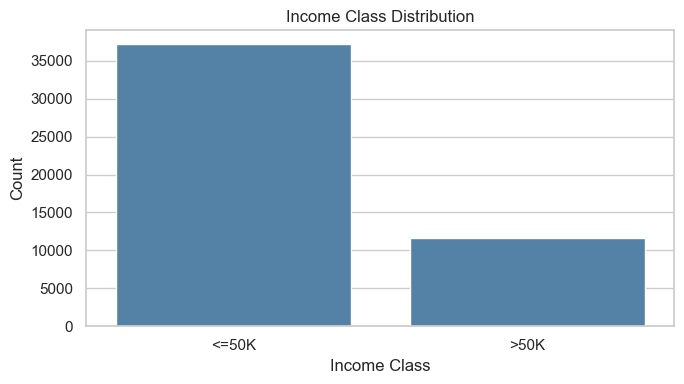

In [3]:
plt.figure(figsize=(7, 4))
sns.countplot(data=df, x="income", color="steelblue")
plt.title("Income Class Distribution")
plt.xlabel("Income Class")
plt.ylabel("Count")
plt.tight_layout()
plt.show()

## EDA — Numerical Features

,count,mean,std,min,25%,50%,75%,max
age,48842.0,38.643585,13.710510,17.0,28.0,37.0,48.0,90.0
fnlwgt,48842.0,189664.134597,105604.025423,12285.0,117550.5,178144.5,237642.0,1490400.0
education-num,48842.0,10.078089,2.570973,1.0,9.0,10.0,12.0,16.0
capital-gain,48842.0,1079.067626,7452.019058,0.0,0.0,0.0,0.0,99999.0
capital-loss,48842.0,87.502314,403.004552,0.0,0.0,0.0,0.0,4356.0
hours-per-week,48842.0,40.422382,12.391444,1.0,40.0,40.0,45.0,99.0


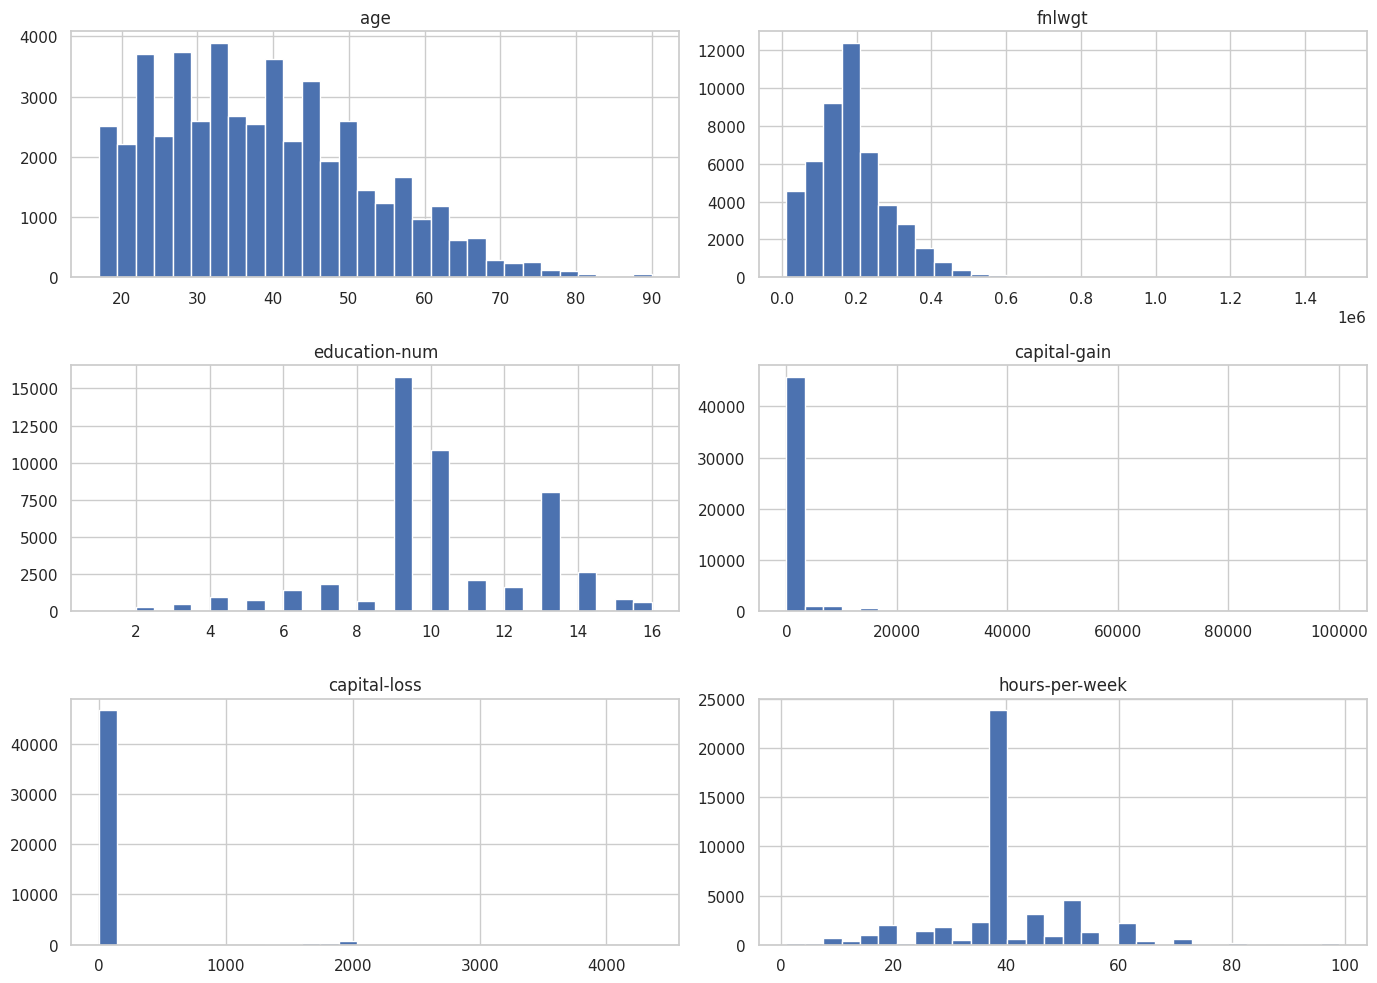

In [4]:
numeric_cols = df.select_dtypes(include=np.number).columns.tolist()
display(df[numeric_cols].describe().T)
df[numeric_cols].hist(figsize=(14, 10), bins=30)
plt.tight_layout()
plt.show()

## EDA — Correlation Heatmap

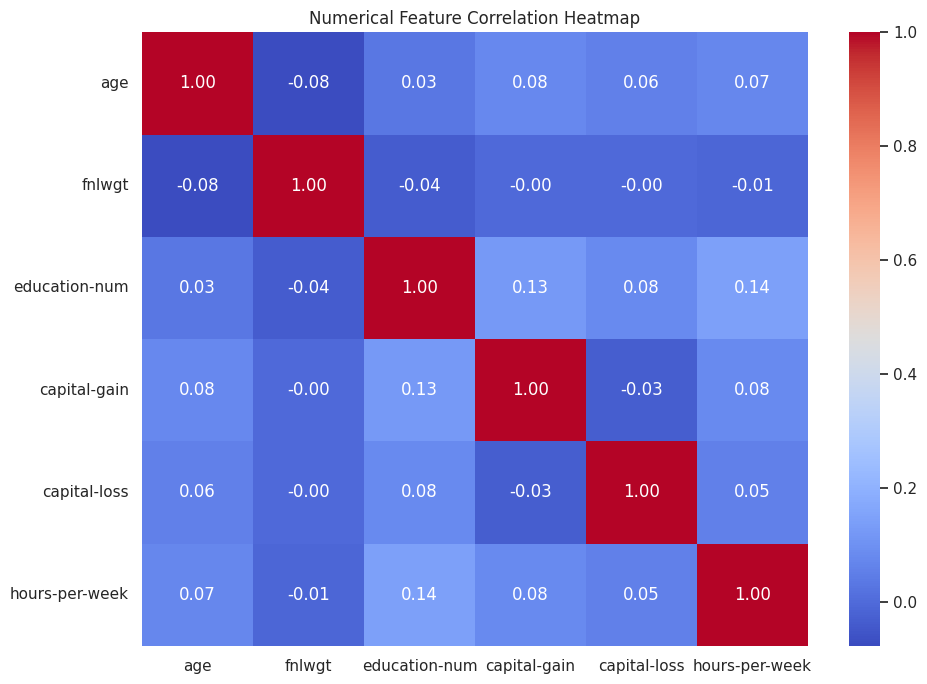

In [5]:
plt.figure(figsize=(10, 7))
sns.heatmap(df.select_dtypes(include=np.number).corr(), annot=True, fmt=".2f", cmap="coolwarm")
plt.title("Numerical Feature Correlation Heatmap")
plt.tight_layout()
plt.show()

## Prepare Data

In [6]:
X_train, X_test, y_train, y_test = split_adult(df)
preprocessor = build_preprocessor(X_train)
print("Training rows:", X_train.shape[0])
print("Test rows:", X_test.shape[0])
print("Training class distribution:")
display(y_train.value_counts(normalize=True).rename("proportion").to_frame())
print("Preprocessing is kept inside the Pipeline so imputers, encoders, and scalers are fitted on training data only.")

Training rows: 39073
Test rows: 9769
Training class distribution:


,proportion
income,
0,0.76073
1,0.23927


Preprocessing is kept inside the Pipeline so imputers, encoders, and scalers are fitted on training data only.


## Build and Train Model

In [7]:
from sklearn.ensemble import AdaBoostClassifier

In [8]:
model = AdaBoostClassifier(n_estimators=100, learning_rate=0.5, random_state=RANDOM_STATE)
pipeline = Pipeline(steps=[("preprocessor", preprocessor), ("model", model)])
pipeline.fit(X_train, y_train)
y_pred = pipeline.predict(X_test)
y_score = pipeline.predict_proba(X_test)[:, 1]

base_result = {
    "model": "AdaBoost Classifier",
    "accuracy": accuracy_score(y_test, y_pred),
    "precision_weighted": precision_score(y_test, y_pred, average="weighted", zero_division=0),
    "recall_weighted": recall_score(y_test, y_pred, average="weighted", zero_division=0),
    "f1_weighted": f1_score(y_test, y_pred, average="weighted", zero_division=0),
    "roc_auc": roc_auc_score(y_test, y_score),
}
print("Base model metrics")
display(pd.DataFrame([base_result]).round(4))
print(classification_report(y_test, y_pred, target_names=["<=50K", ">50K"], zero_division=0))

Base model metrics


,model,accuracy,precision_weighted,recall_weighted,f1_weighted,roc_auc
0,AdaBoost Classifier,0.8569,0.8512,0.8569,0.8469,0.907


              precision    recall  f1-score   support

       <=50K       0.87      0.96      0.91      7431
        >50K       0.79      0.54      0.65      2338

    accuracy                           0.86      9769
   macro avg       0.83      0.75      0.78      9769
weighted avg       0.85      0.86      0.85      9769



## Confusion Matrix

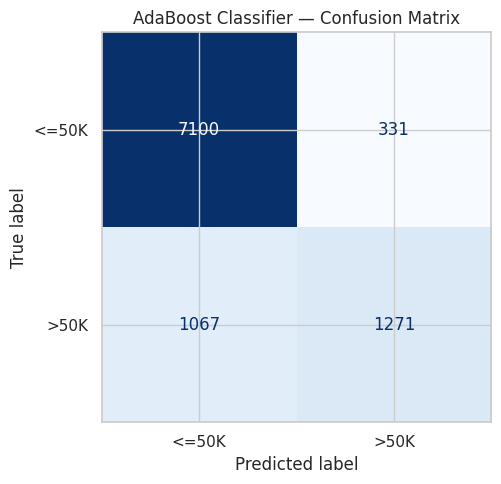

In [9]:
cm = confusion_matrix(y_test, y_pred)
disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=["<=50K", ">50K"])
fig, ax = plt.subplots(figsize=(6, 5))
disp.plot(ax=ax, values_format="d", cmap="Blues", colorbar=False)
ax.set_title("AdaBoost Classifier — Confusion Matrix")
plt.tight_layout()
plt.show()

## Hyperparameter Tuning

Fitting 2 folds for each of 4 candidates, totalling 8 fits


Spreadsheet runtime warmup failed during python startup
Traceback (most recent call last):
  File "/tmp/tmp.QlpUkOUI9D/artifact_tool_v2-2.8.66/artifact_tool/patches/warm_spreadsheet_runtime_on_startup.py", line 26, in warm_spreadsheet_runtime_on_startup
  File "/tmp/tmp.QlpUkOUI9D/artifact_tool_v2-2.8.66/artifact_tool/spreadsheet_warmup.py", line 785, in warm_spreadsheet_runtime
  File "/tmp/tmp.QlpUkOUI9D/artifact_tool_v2-2.8.66/artifact_tool/spreadsheet_warmup.py", line 718, in _warm_feature_flows
  File "/tmp/tmp.QlpUkOUI9D/artifact_tool_v2-2.8.66/artifact_tool/spreadsheet_warmup.py", line 509, in _warm_drawing_and_image_flows
  File "/tmp/tmp.QlpUkOUI9D/artifact_tool_v2-2.8.66/artifact_tool/generated/interface/models.py", line 32861, in bring_to_front
  File "/tmp/tmp.QlpUkOUI9D/artifact_tool_v2-2.8.66/artifact_tool/rpc/remote.py", line 764, in __call__
  File "/tmp/tmp.QlpUkOUI9D/artifact_tool_v2-2.8.66/artifact_tool/rpc/client.py", line 175, in call
artifact_tool.rpc.client.Remot

Spreadsheet runtime warmup failed during python startup
Traceback (most recent call last):
  File "/tmp/tmp.QlpUkOUI9D/artifact_tool_v2-2.8.66/artifact_tool/patches/warm_spreadsheet_runtime_on_startup.py", line 26, in warm_spreadsheet_runtime_on_startup
  File "/tmp/tmp.QlpUkOUI9D/artifact_tool_v2-2.8.66/artifact_tool/spreadsheet_warmup.py", line 785, in warm_spreadsheet_runtime
  File "/tmp/tmp.QlpUkOUI9D/artifact_tool_v2-2.8.66/artifact_tool/spreadsheet_warmup.py", line 718, in _warm_feature_flows
  File "/tmp/tmp.QlpUkOUI9D/artifact_tool_v2-2.8.66/artifact_tool/spreadsheet_warmup.py", line 509, in _warm_drawing_and_image_flows
  File "/tmp/tmp.QlpUkOUI9D/artifact_tool_v2-2.8.66/artifact_tool/generated/interface/models.py", line 32861, in bring_to_front
  File "/tmp/tmp.QlpUkOUI9D/artifact_tool_v2-2.8.66/artifact_tool/rpc/remote.py", line 764, in __call__
  File "/tmp/tmp.QlpUkOUI9D/artifact_tool_v2-2.8.66/artifact_tool/rpc/client.py", line 175, in call
artifact_tool.rpc.client.Remot

Spreadsheet runtime warmup failed during python startup
Traceback (most recent call last):
  File "/tmp/tmp.QlpUkOUI9D/artifact_tool_v2-2.8.66/artifact_tool/patches/warm_spreadsheet_runtime_on_startup.py", line 26, in warm_spreadsheet_runtime_on_startup
  File "/tmp/tmp.QlpUkOUI9D/artifact_tool_v2-2.8.66/artifact_tool/spreadsheet_warmup.py", line 785, in warm_spreadsheet_runtime
  File "/tmp/tmp.QlpUkOUI9D/artifact_tool_v2-2.8.66/artifact_tool/spreadsheet_warmup.py", line 718, in _warm_feature_flows
  File "/tmp/tmp.QlpUkOUI9D/artifact_tool_v2-2.8.66/artifact_tool/spreadsheet_warmup.py", line 509, in _warm_drawing_and_image_flows
  File "/tmp/tmp.QlpUkOUI9D/artifact_tool_v2-2.8.66/artifact_tool/generated/interface/models.py", line 32861, in bring_to_front
  File "/tmp/tmp.QlpUkOUI9D/artifact_tool_v2-2.8.66/artifact_tool/rpc/remote.py", line 764, in __call__
  File "/tmp/tmp.QlpUkOUI9D/artifact_tool_v2-2.8.66/artifact_tool/rpc/client.py", line 175, in call
artifact_tool.rpc.client.Remot

Spreadsheet runtime warmup failed during python startup
Traceback (most recent call last):
  File "/tmp/tmp.QlpUkOUI9D/artifact_tool_v2-2.8.66/artifact_tool/patches/warm_spreadsheet_runtime_on_startup.py", line 26, in warm_spreadsheet_runtime_on_startup
  File "/tmp/tmp.QlpUkOUI9D/artifact_tool_v2-2.8.66/artifact_tool/spreadsheet_warmup.py", line 785, in warm_spreadsheet_runtime
  File "/tmp/tmp.QlpUkOUI9D/artifact_tool_v2-2.8.66/artifact_tool/spreadsheet_warmup.py", line 718, in _warm_feature_flows
  File "/tmp/tmp.QlpUkOUI9D/artifact_tool_v2-2.8.66/artifact_tool/spreadsheet_warmup.py", line 509, in _warm_drawing_and_image_flows
  File "/tmp/tmp.QlpUkOUI9D/artifact_tool_v2-2.8.66/artifact_tool/generated/interface/models.py", line 32861, in bring_to_front
  File "/tmp/tmp.QlpUkOUI9D/artifact_tool_v2-2.8.66/artifact_tool/rpc/remote.py", line 764, in __call__
  File "/tmp/tmp.QlpUkOUI9D/artifact_tool_v2-2.8.66/artifact_tool/rpc/client.py", line 175, in call
artifact_tool.rpc.client.Remot

Spreadsheet runtime warmup failed during python startup
Traceback (most recent call last):
  File "/tmp/tmp.QlpUkOUI9D/artifact_tool_v2-2.8.66/artifact_tool/patches/warm_spreadsheet_runtime_on_startup.py", line 26, in warm_spreadsheet_runtime_on_startup
  File "/tmp/tmp.QlpUkOUI9D/artifact_tool_v2-2.8.66/artifact_tool/spreadsheet_warmup.py", line 785, in warm_spreadsheet_runtime
  File "/tmp/tmp.QlpUkOUI9D/artifact_tool_v2-2.8.66/artifact_tool/spreadsheet_warmup.py", line 718, in _warm_feature_flows
  File "/tmp/tmp.QlpUkOUI9D/artifact_tool_v2-2.8.66/artifact_tool/spreadsheet_warmup.py", line 509, in _warm_drawing_and_image_flows
  File "/tmp/tmp.QlpUkOUI9D/artifact_tool_v2-2.8.66/artifact_tool/generated/interface/models.py", line 32861, in bring_to_front
  File "/tmp/tmp.QlpUkOUI9D/artifact_tool_v2-2.8.66/artifact_tool/rpc/remote.py", line 764, in __call__
  File "/tmp/tmp.QlpUkOUI9D/artifact_tool_v2-2.8.66/artifact_tool/rpc/client.py", line 175, in call
artifact_tool.rpc.client.Remot

Best parameters: {'model__learning_rate': 0.7, 'model__n_estimators': 200}
Best cross-validation weighted F1: 0.8467


,model,accuracy,precision_weighted,recall_weighted,f1_weighted,roc_auc
0,AdaBoost Classifier,0.8569,0.8512,0.8569,0.8469,0.907
1,AdaBoost Classifier (Tuned),0.8581,0.8519,0.8581,0.8502,0.911


Tuned model confusion matrix:


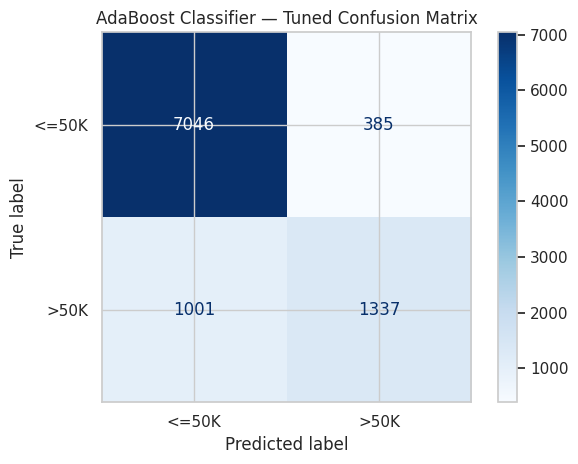

In [10]:
# Small, rubric-aligned search grid. Two-fold CV limits runtime while comparing settings fairly.
param_grid = {'model__n_estimators': [100, 200], 'model__learning_rate': [0.3, 0.7]}
cv = StratifiedKFold(n_splits=2, shuffle=True, random_state=RANDOM_STATE)
grid_search = GridSearchCV(
    estimator=Pipeline(steps=[("preprocessor", build_preprocessor(X_train)), ("model", AdaBoostClassifier(n_estimators=100, learning_rate=0.5, random_state=RANDOM_STATE))]),
    param_grid=param_grid,
    scoring="f1_weighted",
    cv=cv,
    n_jobs=-1,
    verbose=1,
    refit=True,
)
grid_search.fit(X_train, y_train)
tuned_pipeline = grid_search.best_estimator_
tuned_pred = tuned_pipeline.predict(X_test)
tuned_score = tuned_pipeline.predict_proba(X_test)[:, 1]
tuned_result = {
    "model": "AdaBoost Classifier (Tuned)",
    "accuracy": accuracy_score(y_test, tuned_pred),
    "precision_weighted": precision_score(y_test, tuned_pred, average="weighted", zero_division=0),
    "recall_weighted": recall_score(y_test, tuned_pred, average="weighted", zero_division=0),
    "f1_weighted": f1_score(y_test, tuned_pred, average="weighted", zero_division=0),
    "roc_auc": roc_auc_score(y_test, tuned_score),
}
print("Best parameters:", grid_search.best_params_)
print("Best cross-validation weighted F1:", round(grid_search.best_score_, 4))
display(pd.DataFrame([base_result, tuned_result]).round(4))
print("Tuned model confusion matrix:")
ConfusionMatrixDisplay.from_predictions(y_test, tuned_pred, display_labels=["<=50K", ">50K"], cmap="Blues", values_format="d")
plt.title("AdaBoost Classifier — Tuned Confusion Matrix")
plt.tight_layout()
plt.show()

## Result

In [11]:
results = pd.DataFrame([base_result, tuned_result])
results_path = PROJECT_ROOT / "results" / "review2_classification" / ("07_adaboost_classifier.csv" )
results_path.parent.mkdir(parents=True, exist_ok=True)
results.to_csv(results_path, index=False)
print("Saved:", results_path)
display(results.round(4))

Saved: /mnt/data/Review-2-Final/Review-2/results/review2_classification/07_adaboost_classifier.csv


,model,accuracy,precision_weighted,recall_weighted,f1_weighted,roc_auc
0,AdaBoost Classifier,0.8569,0.8512,0.8569,0.8469,0.907
1,AdaBoost Classifier (Tuned),0.8581,0.8519,0.8581,0.8502,0.911
